# Heart Disease Prediction

## Exploratory Data Analysis, Preprocessing and Machine Learning

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

## 1. Load Dataset

In [2]:
heart_df = pd.read_csv('heart.csv')
heart_df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
print('Dataset shape:', heart_df.shape)

Dataset shape: (918, 12)


In [4]:
heart_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [5]:
heart_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


## 2. Data Quality Checks

In [6]:
print('Duplicate records:', heart_df.duplicated().sum())

print('\nMissing values:')
print(heart_df.isnull().sum())

Duplicate records: 0

Missing values:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


In [7]:
heart_df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')

## 3. Exploratory Data Analysis

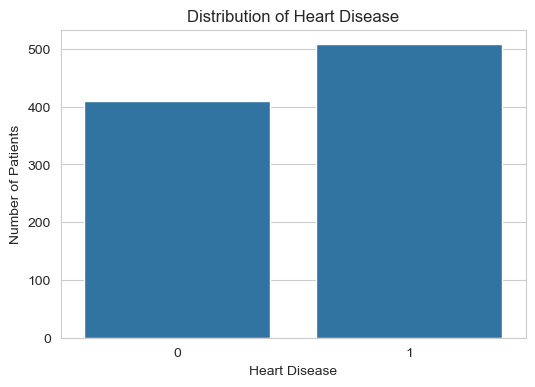

In [8]:
plt.figure(figsize=(6, 4))
sns.countplot(data=heart_df, x='HeartDisease')
plt.title('Distribution of Heart Disease')
plt.xlabel('Heart Disease')
plt.ylabel('Number of Patients')
plt.show()

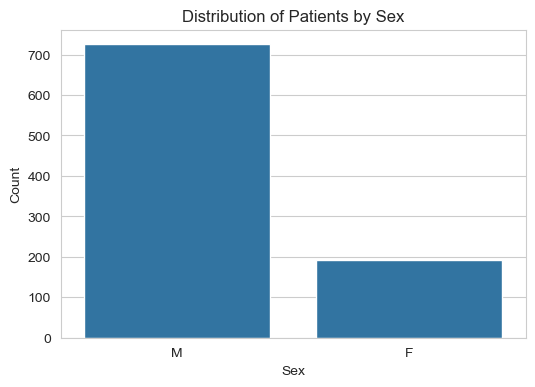

In [9]:
plt.figure(figsize=(6, 4))
sns.countplot(data=heart_df, x='Sex')
plt.title('Distribution of Patients by Sex')
plt.xlabel('Sex')
plt.ylabel('Count')
plt.show()

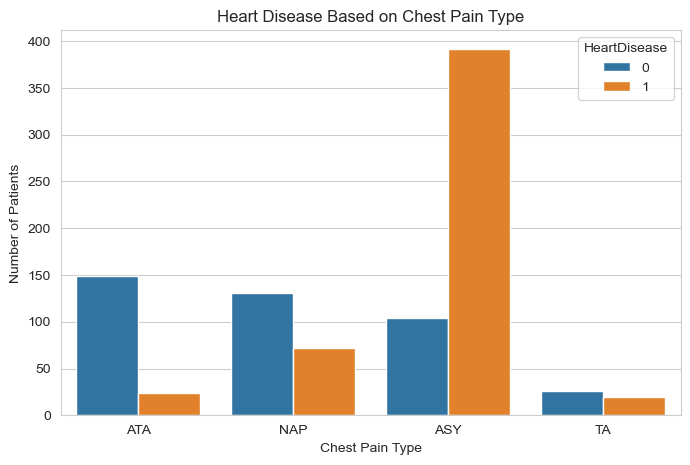

In [10]:
plt.figure(figsize=(8, 5))
sns.countplot(data=heart_df, x='ChestPainType', hue='HeartDisease')
plt.title('Heart Disease Based on Chest Pain Type')
plt.xlabel('Chest Pain Type')
plt.ylabel('Number of Patients')
plt.show()

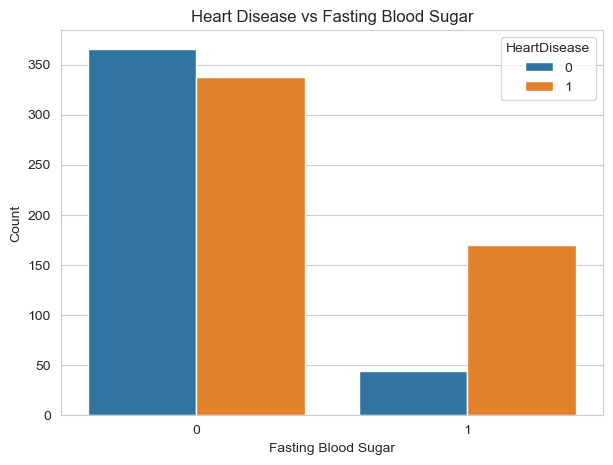

In [11]:
plt.figure(figsize=(7, 5))
sns.countplot(data=heart_df, x='FastingBS', hue='HeartDisease')
plt.title('Heart Disease vs Fasting Blood Sugar')
plt.xlabel('Fasting Blood Sugar')
plt.ylabel('Count')
plt.show()

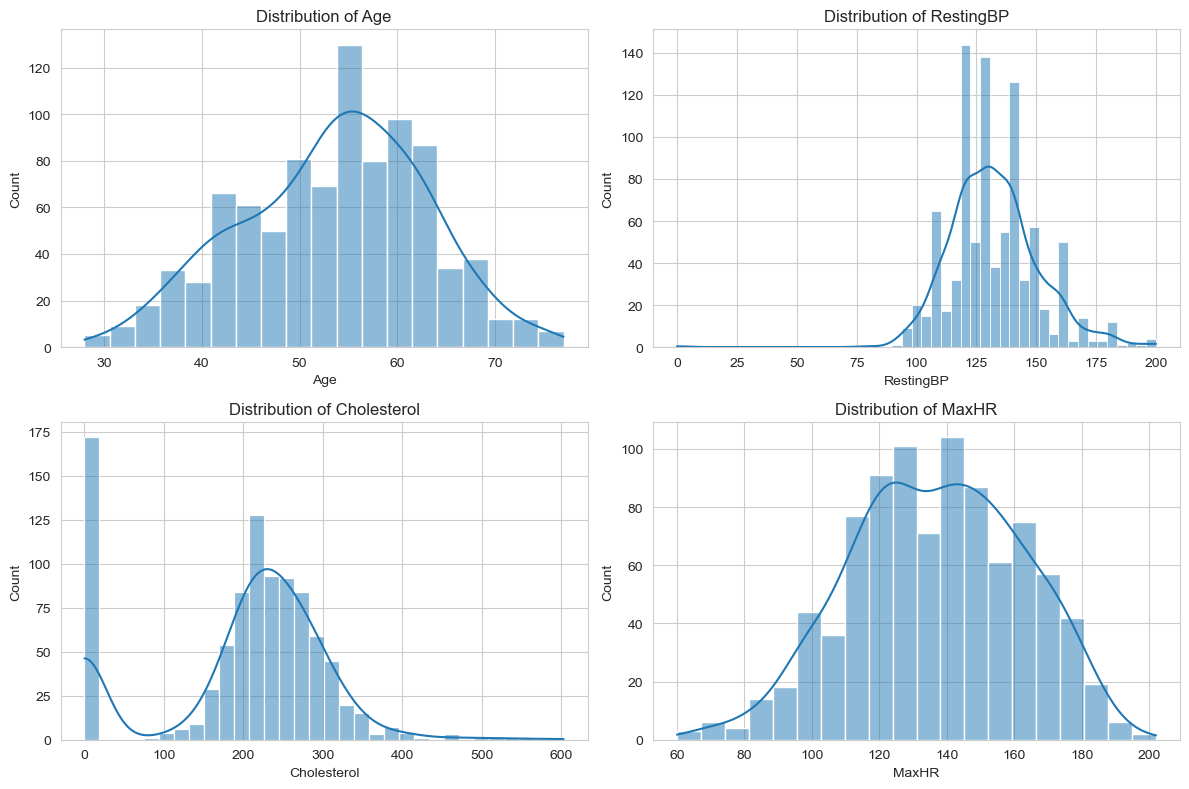

In [12]:
numeric_features = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flatten(), numeric_features):
    sns.histplot(data=heart_df, x=feature, kde=True, ax=ax)
    ax.set_title(f'Distribution of {feature}')

plt.tight_layout()
plt.show()

## 4. Check Invalid Zero Values

In [13]:
zero_counts = (heart_df == 0).sum()
zero_counts

Age                 0
Sex                 0
ChestPainType       0
RestingBP           1
Cholesterol       172
FastingBS         704
RestingECG          0
MaxHR               0
ExerciseAngina      0
Oldpeak           368
ST_Slope            0
HeartDisease      410
dtype: int64

### Replace zero Cholesterol values with the mean of valid observations

In [14]:
valid_cholesterol = heart_df.loc[heart_df['Cholesterol'] > 0, 'Cholesterol']
cholesterol_mean = valid_cholesterol.mean()

heart_df.loc[heart_df['Cholesterol'] == 0, 'Cholesterol'] = cholesterol_mean
heart_df['Cholesterol'] = heart_df['Cholesterol'].round(2)

print('Cholesterol zero values replaced.')

Cholesterol zero values replaced.


### Replace zero RestingBP values with the mean of valid observations

In [15]:
valid_bp = heart_df.loc[heart_df['RestingBP'] > 0, 'RestingBP']
bp_mean = valid_bp.mean()

heart_df.loc[heart_df['RestingBP'] == 0, 'RestingBP'] = bp_mean
heart_df['RestingBP'] = heart_df['RestingBP'].round(2)

print('RestingBP zero values replaced.')

RestingBP zero values replaced.


## 5. Additional EDA

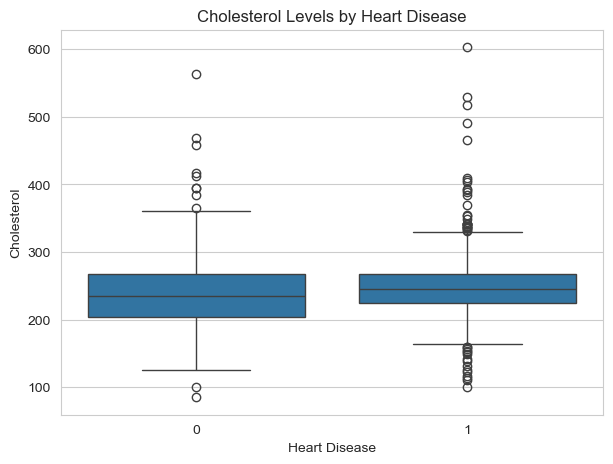

In [16]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=heart_df, x='HeartDisease', y='Cholesterol')
plt.title('Cholesterol Levels by Heart Disease')
plt.xlabel('Heart Disease')
plt.ylabel('Cholesterol')
plt.show()

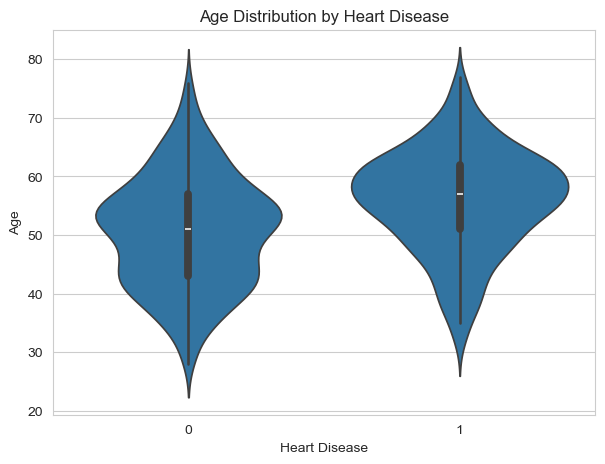

In [17]:
plt.figure(figsize=(7, 5))
sns.violinplot(data=heart_df, x='HeartDisease', y='Age')
plt.title('Age Distribution by Heart Disease')
plt.xlabel('Heart Disease')
plt.ylabel('Age')
plt.show()

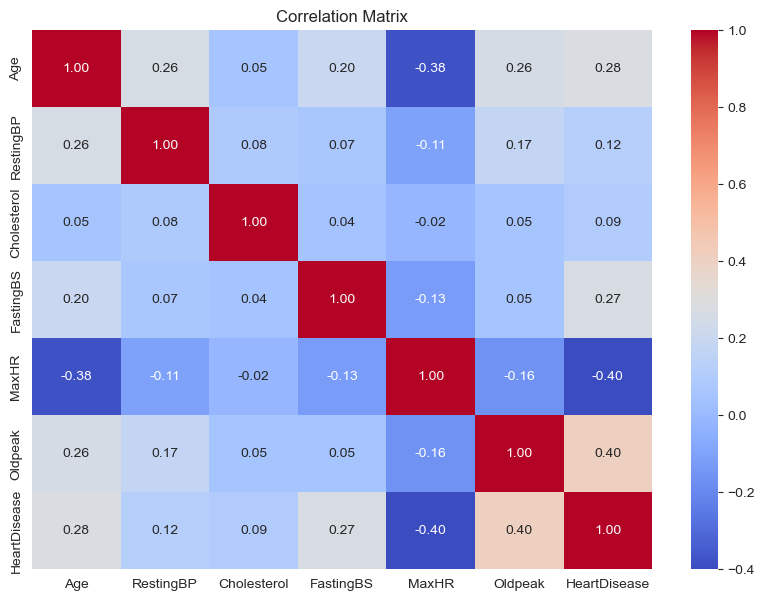

In [18]:
correlation = heart_df.corr(numeric_only=True)

plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

## 6. Data Preprocessing

In [19]:
X = heart_df.drop(columns='HeartDisease')
y = heart_df['HeartDisease']

print('Feature shape:', X.shape)
print('Target shape:', y.shape)

Feature shape: (918, 11)
Target shape: (918,)


In [20]:
X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)
X_encoded.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140.0,289.0,0,172,0.0,1,1,0,0,1,0,0,0,1
1,49,160.0,180.0,0,156,1.0,0,0,1,0,1,0,0,1,0
2,37,130.0,283.0,0,98,0.0,1,1,0,0,0,1,0,0,1
3,48,138.0,214.0,0,108,1.5,0,0,0,0,1,0,1,1,0
4,54,150.0,195.0,0,122,0.0,1,0,1,0,1,0,0,0,1


In [21]:
print('Features after encoding:', X_encoded.shape[1])
print('\nFeature names:')
print(X_encoded.columns.tolist())

Features after encoding: 15

Feature names:
['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up']


## 7. Train-Test Split

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('Training samples:', X_train.shape[0])
print('Testing samples:', X_test.shape[0])

Training samples: 734
Testing samples: 184


## 8. Feature Scaling

In [23]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Feature scaling completed.')

Feature scaling completed.


## 9. Model Training and Comparison

In [24]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Gaussian Naive Bayes': GaussianNB(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Support Vector Machine': SVC(kernel='rbf', probability=True, random_state=42)
}

results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'F1 Score': f1_score(y_test, predictions)
    })

In [25]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('Accuracy', ascending=False).reset_index(drop=True)

results_df.round(4)

,Model,Accuracy,F1 Score
0,Logistic Regression,0.8913,0.9029
1,K-Nearest Neighbors,0.8913,0.9029
2,Gaussian Naive Bayes,0.8750,0.8844
3,Support Vector Machine,0.8587,0.8750
4,Decision Tree,0.7500,0.7723


## 10. Accuracy Comparison

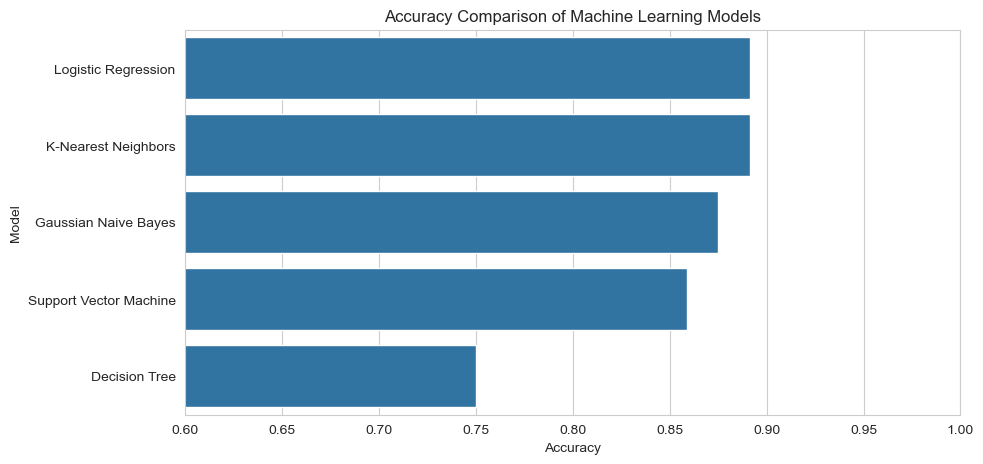

In [26]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x='Accuracy', y='Model')
plt.title('Accuracy Comparison of Machine Learning Models')
plt.xlabel('Accuracy')
plt.ylabel('Model')
plt.xlim(0.6, 1.0)
plt.show()

## 11. F1 Score Comparison

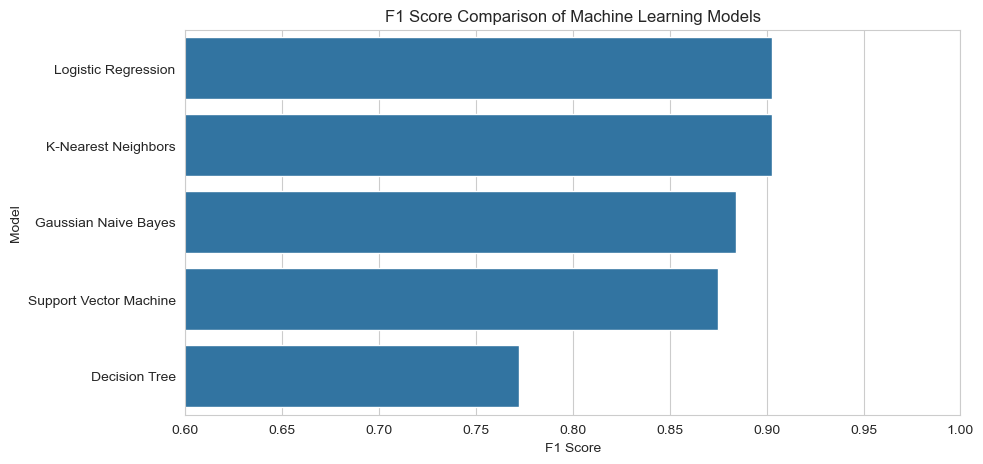

In [27]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x='F1 Score', y='Model')
plt.title('F1 Score Comparison of Machine Learning Models')
plt.xlabel('F1 Score')
plt.ylabel('Model')
plt.xlim(0.6, 1.0)
plt.show()

## 12. Select and Train the Final Model

In [28]:
best_model_name = results_df.loc[0, 'Model']
print('Best performing model:', best_model_name)

final_knn = KNeighborsClassifier(n_neighbors=5)
final_knn.fit(X_train_scaled, y_train)

final_predictions = final_knn.predict(X_test_scaled)

Best performing model: Logistic Regression


In [29]:
final_accuracy = accuracy_score(y_test, final_predictions)
final_f1 = f1_score(y_test, final_predictions)

print(f'Final KNN Accuracy : {final_accuracy:.4f}')
print(f'Final KNN F1 Score : {final_f1:.4f}')

Final KNN Accuracy : 0.8913
Final KNN F1 Score : 0.9029


In [30]:
print(classification_report(
    y_test,
    final_predictions,
    target_names=['No Heart Disease', 'Heart Disease']
))

                  precision    recall  f1-score   support

No Heart Disease       0.89      0.87      0.88        82
   Heart Disease       0.89      0.91      0.90       102

        accuracy                           0.89       184
       macro avg       0.89      0.89      0.89       184
    weighted avg       0.89      0.89      0.89       184



## 13. Save the Trained Model

In [31]:
import joblib

joblib.dump(final_knn, 'heart_disease_knn.pkl')
joblib.dump(scaler, 'heart_disease_scaler.pkl')
joblib.dump(X_encoded.columns.tolist(), 'heart_disease_features.pkl')

print('Model, scaler and feature names saved successfully.')

Model, scaler and feature names saved successfully.


In [32]:
import os

files = [
    'heart_disease_knn.pkl',
    'heart_disease_scaler.pkl',
    'heart_disease_features.pkl'
]

for file in files:
    print(file, '->', os.path.exists(file))

heart_disease_knn.pkl -> True
heart_disease_scaler.pkl -> True
heart_disease_features.pkl -> True
